# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
**Nguyễn Sơn Giang** · `dataset_version` d10-21e4070301 · kết quả và trả lời câu hỏi: [`REPORT.md`](REPORT.md)

**Cách chạy.** Máy cá nhân không có GPU nên mọi bước cần GPU chạy trên **Kaggle Notebooks (Tesla T4 16 GB)** — cùng loại GPU với Colab T4 của đề. Mã của tôi nằm trong `lab/` (không sửa `scripts/`, `tests/`):

| File | Vai trò |
|---|---|
| `lab/labels.py` | YOLO → JSON thang 0–1000 (hoặc pixel), prompt |
| `lab/vlm.py` | nạp 4-bit (ViT/projector/lm_head fp16), `encode_example` + mask loss, `collate`, `apply_setup` E1/E2/E3, nạp lại adapter + projector |
| `lab/run.py` | `smoke`, `e0`, `train` (huấn luyện + suy luận test, ghi `run.json`) |
| `lab/grpo.py`, `lab/reward.py` | E5: GRPO (`trl.GRPOTrainer`) với reward IoU |
| `lab/viz.py`, `lab/paired.py` | ảnh minh hoạ, bảng tổng hợp, bootstrap ghép cặp |
| `kaggle/push.py`, `kaggle/fetch.py` | đóng gói `lab/`+`scripts/` thành kernel Kaggle T4 và push; tải `*.jsonl`/log về rồi chấm bằng `scripts/score.py` |

Notebook này được chạy trên máy local (CPU): các ô dữ liệu, nhãn, chấm điểm, phân tích chạy thật; các ô GPU in **log thật** của kernel Kaggle tương ứng (`runs/<exp>/kernel.log`, `report/logs/`).

## 0. Môi trường

In [1]:
# Trên Kaggle (mỗi thí nghiệm một kernel, GPU T4, internet bật, dataset Kaggle gắn làm input):
#   python kaggle/push.py smoke | e0 | e1 -- --setup E1 | e2 -- --setup E2 | e3 -- --setup E3
#   python kaggle/push.py e4_data_0.1 -- --setup E3 --train-frac 0.1
#   python kaggle/push.py e5 --from lab10-e3 -- --impl trl
#   python kaggle/fetch.py <exp>     # tải *.jsonl + run.json + log, chấm bằng scripts/score.py
import json, re
from pathlib import Path

def kernel_log(name):
    p = Path(f"runs/{name}/kernel.log")
    if not p.exists():  # log Kaggle dạng JSON [{"data": ...}]
        raw = next(Path(f"runs/{name}").glob("*.log"))
        p.write_text("".join(r["data"] for r in json.loads(raw.read_text(encoding="utf-8"))), encoding="utf-8")
    return p.read_text(encoding="utf-8").splitlines()

print([l for l in kernel_log("e1") if l.startswith("GPU ")])
print([l for l in kernel_log("e1") if re.match(r"^2\.\d+\.\d+\+cu", l)], "(torch, transformers, peft, trl, bitsandbytes)")

['GPU 0: Tesla T4 (UUID: GPU-2590184e-99ff-ff9a-4b02-b3ace6cd07b6)', 'GPU 1: Tesla T4 (UUID: GPU-f3b88894-150e-3a7c-5234-ad787819110b)']
['2.11.0+cu128 5.19.0 0.21.2 1.9.2 0.50.2'] (torch, transformers, peft, trl, bitsandbytes)


In [2]:
# Test gốc của đề. Bỏ chọn đúng 1 test: test_report_template_has_student_markers_and_ten_questions
# kiểm tra REPORT.md *còn* chuỗi '<điền' (mẫu trống) — mâu thuẫn với check_submission.py (bắt buộc *không còn*),
# nên luôn FAIL sau khi điền báo cáo. Không sửa tests/.
!python -m pytest -q -p no:cacheprovider --color=no --deselect tests/test_configs_and_docs.py::test_report_template_has_student_markers_and_ten_questions
!python scripts/check_submission.py

..........................s.........................................     [100%]
67 passed, 1 skipped, 1 deselected in 1.96s


[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[PASS] REPORT.md đã điền — còn chuỗi '<điền'
[PASS] git commits — 12/5
[PASS] git forbidden files

0 FAIL, 0 WARN


## 1. Dữ liệu: tải và chia split theo phiên quay

In [3]:
# Đã chạy: python scripts/prepare_data.py --kaggle
from collections import Counter
from scripts.labcommon import read_jsonl
meta = json.loads(Path("data/splits/meta.json").read_text(encoding="utf-8"))
print("dataset_version:", meta["dataset_version"])
sess = {}
for s in ("train", "val", "test"):
    rows = read_jsonl(f"data/splits/{s}.jsonl")
    sess[s] = Counter(r["session"] for r in rows)
    boxes = Counter(o["label"] for r in rows for o in r["objects"])
    print(f"{s:5s} {len(rows):5d} ảnh  {len(sess[s]):2d} session  pothole={boxes['pothole']:4d} crack={boxes['crack']:4d} manhole={boxes['manhole']:4d}")
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    print(f"session chung {a}/{b}:", set(sess[a]) & set(sess[b]) or "không có")
print("session test:", dict(sess["test"]))

dataset_version: d10-21e4070301
train  1422 ảnh  13 session  pothole=1074 crack=1750 manhole= 691
val     276 ảnh   2 session  pothole=  66 crack= 470 manhole= 103
test    311 ảnh   3 session  pothole= 121 crack= 299 manhole= 163
session chung train/val: không có
session chung train/test: không có
session chung val/test: không có
session test: {'num-4': 15, 'vlc-2025-02-18-23': 213, 'vlc-2025-02-19-17': 83}


saved report/figures/gt_samples.jpg


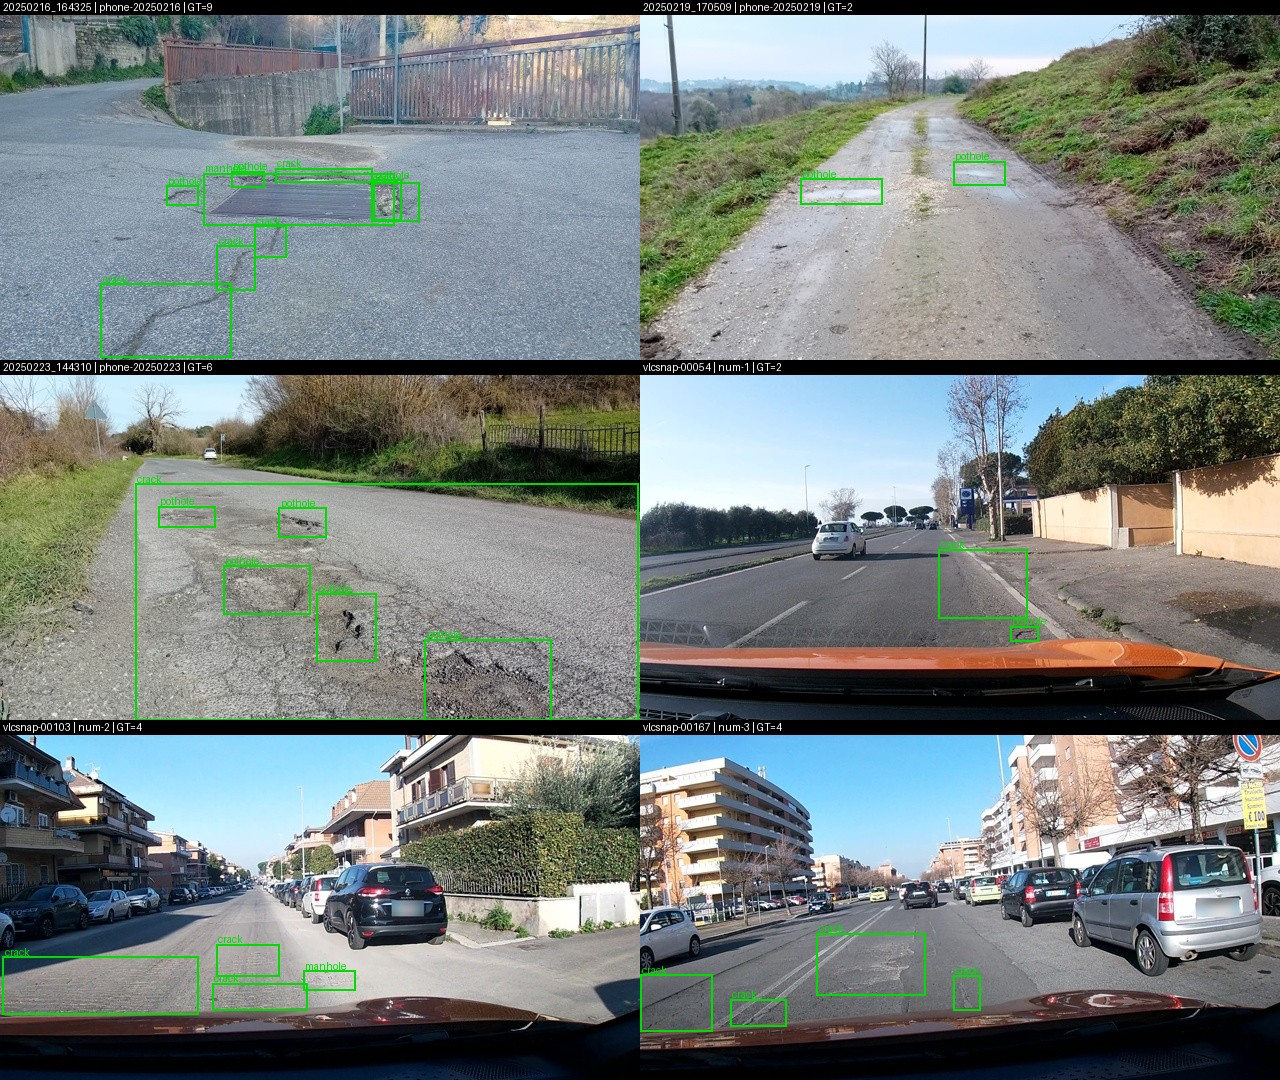

In [4]:
from IPython.display import Image, display
!python -m lab.viz gt --out report/figures/gt_samples.jpg
display(Image("report/figures/gt_samples.jpg", width=900))

## 2. Nhãn: YOLO → JSON thang 0–1000

In [5]:
from lab.labels import PROMPT_NORM1000, objects_to_answer, yolo_to_box
from scripts.score import _gt_boxes, iou_xyxy, parse_output
e = next(r for r in read_jsonl("data/splits/train.jsonl") if len(r["objects"]) >= 3)
print(PROMPT_NORM1000, "\n")
print("YOLO :", e["objects"][:2])
ans = objects_to_answer(e["objects"])
print("JSON :", ans)
# Kiểm tra khứ hồi: JSON -> box -> so với GT trọng tài dùng
ious = [max(iou_xyxy(p["bbox"], g["bbox"]) for g in _gt_boxes(e)) for p in parse_output(ans)]
print("IoU khứ hồi:", [round(v, 3) for v in ious])

Locate road damage in this image. Detect only objects of classes: pothole, crack, manhole. Output only a JSON list of objects with label and bbox_2d coordinates normalized on a 0-1000 scale: [{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. If no damage is found, output []. 

YOLO : [{'label': 'manhole', 'yolo': [0.466407, 0.552778, 0.298437, 0.144444]}, {'label': 'pothole', 'yolo': [0.604688, 0.556944, 0.043751, 0.113889]}]
JSON : [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
IoU khứ hồi: [0.977, 0.993, 0.995, 0.985, 0.988, 0.982, 0.989, 0.986, 0.996]


In [6]:
!python -m pytest lab/tests -q -p no:cacheprovider --color=no

..............                                                           [100%]
14 passed in 0.05s


### Kiểm chứng thang toạ độ (Câu 3): nhãn GT qua bộ chuyển đổi, chấm đúng/sai thang

In [7]:
from scripts.labcommon import write_jsonl
test = read_jsonl("data/splits/test.jsonl")
Path("runs/analysis").mkdir(parents=True, exist_ok=True)
write_jsonl("runs/analysis/oracle_norm1000.jsonl", [{"image_id": e["image_id"], "raw": objects_to_answer(e["objects"])} for e in test])
write_jsonl("runs/analysis/oracle_pixel.jsonl", [{"image_id": e["image_id"], "raw": objects_to_answer(e["objects"], "pixel", e["width"], e["height"])} for e in test])
!python scripts/score.py --pred runs/analysis/oracle_norm1000.jsonl --name ORACLE_norm1000 --out runs/analysis/o1.json --n-boot 100 | head -1
!python scripts/score.py --pred runs/analysis/oracle_pixel.jsonl --coord pixel --name ORACLE_pixel_as_pixel --out runs/analysis/o2.json --n-boot 100 | head -1
!python scripts/score.py --pred runs/analysis/oracle_pixel.jsonl --name ORACLE_pixel_as_norm1000 --out runs/analysis/o3.json --n-boot 100 | head -1
!python scripts/score.py --pred runs/e1/out/e1.jsonl --coord pixel --name E1_as_pixel --out runs/analysis/o4.json --n-boot 100 | head -1

ORACLE_norm1000 [test] n=311 valid=1.000 P=1.000 R=1.000 F1=1.000 CI95=1.000-1.000 meanIoU=0.988 FP/img=0.00


ORACLE_pixel_as_pixel [test] n=311 valid=1.000 P=1.000 R=1.000 F1=1.000 CI95=1.000-1.000 meanIoU=1.000 FP/img=0.00


ORACLE_pixel_as_norm1000 [test] n=311 valid=1.000 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.87


E1_as_pixel [test] n=311 valid=0.990 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.56


## 3. E0: zero-shot (chạy trên Kaggle: `python kaggle/push.py e0`)

In [8]:
print(Path("report/logs/e0_run.json").read_text())
rows = read_jsonl("runs/e0/out/e0.jsonl")
bad = [r for r in rows if parse_output(r["raw"]) is None]
print(f"output hỏng: {len(bad)}/{len(rows)}")
for r in rows[:5]:
    print("  ", r["raw"][:150])
print("Ví dụ output hỏng (lặp vô hạn, bị cắt ở 256 token):")
print("  ", bad[2]["raw"][:300])

{
  "name": "e0",
  "infer_minutes": 15.31,
  "peak_vram_gb": 4.24,
  "param_report": {
    "vit": 306242560,
    "projector": 109105152,
    "llm": 4022468096,
    "lm_head": 0,
    "other": 0
  }
}
output hỏng: 51/311
   [{"label": "manhole", "bbox_2d": [770, 640, 843, 686]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 822]}]
   [{"label": "crack", "bbox_2d": [1, 450, 500, 500]}]
   [{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]
   []
   [{"label": "manhole", "bbox_2d": [257, 627, 325, 657]}]
Ví dụ output hỏng (lặp vô hạn, bị cắt ở 256 token):
   [{"label": "crack", "bbox_2d": [12, 350, 100, 375]}, {"label": "crack", "bbox_2d": [10, 375, 100, 400]}, {"label": "crack", "bbox_2d": [10, 400, 100, 425]}, {"label": "crack", "bbox_2d": [10, 425, 100, 450]}, {"label": "crack", "bbox_2d": [10, 450, 100, 475]}, {"label": "crack", "bbox_2d": [10, 475,


In [9]:
!python scripts/score.py --pred runs/e0/out/e0.jsonl --name E0 --out runs/analysis/nb_e0.json

E0 [test] n=311 valid=0.836 P=0.121 R=0.070 F1=0.089 CI95=0.064-0.115 meanIoU=0.598 FP/img=0.95
   pothole  P=0.286 R=0.066 F1=0.107
   crack    P=0.042 R=0.030 F1=0.035
   manhole  P=0.253 R=0.147 F1=0.186


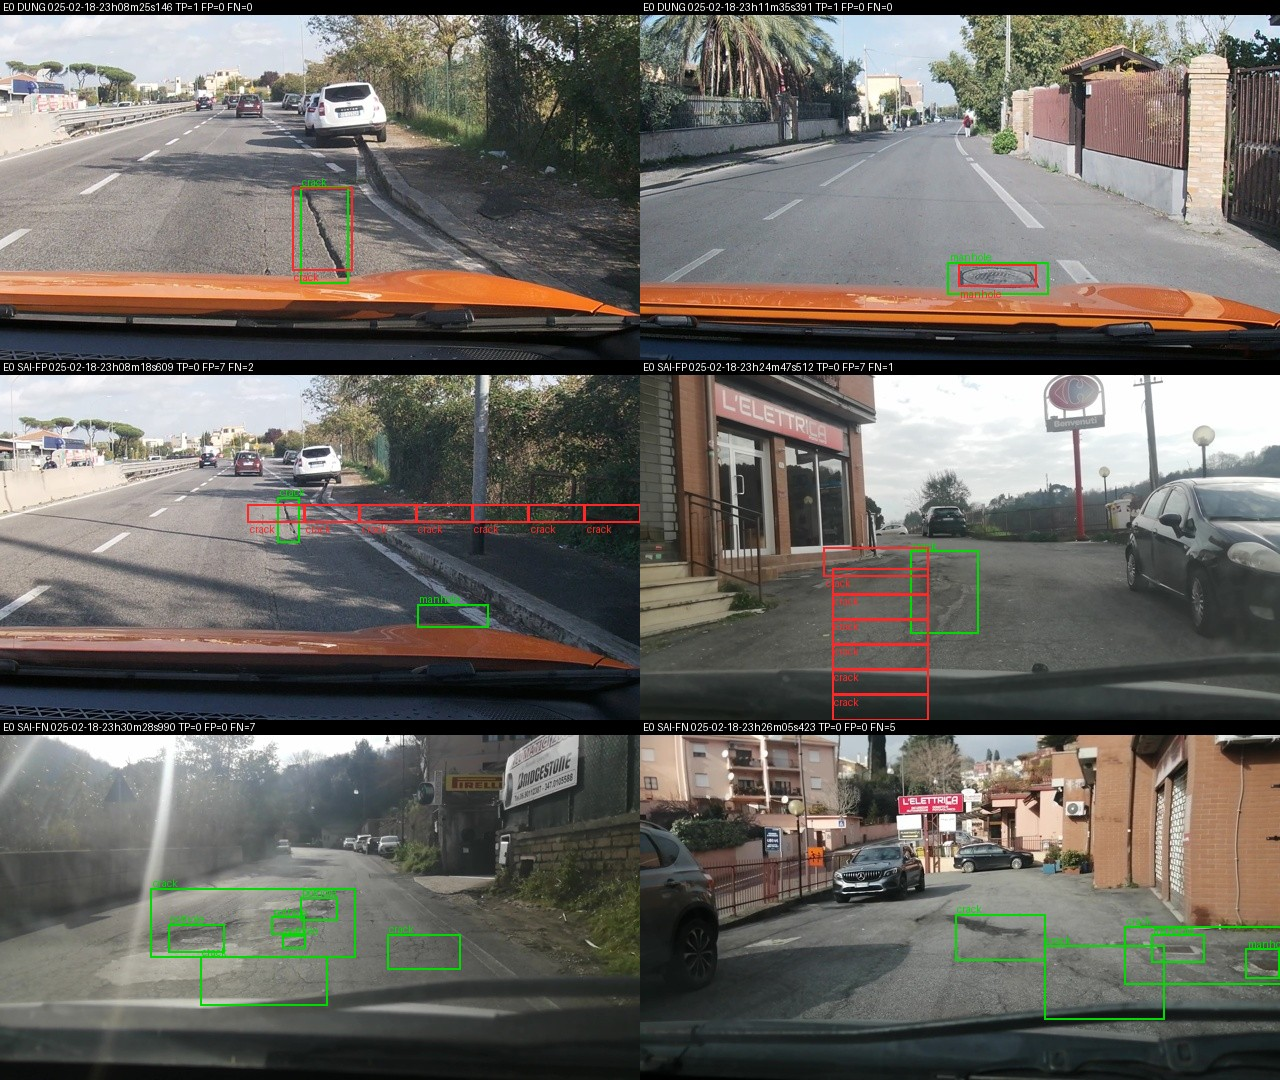

In [10]:
display(Image("report/figures/e0_examples.jpg", width=900))

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss (smoke test trên Kaggle T4)

In [11]:
# python kaggle/push.py smoke  ->  lab.run smoke: cây module, 220 token ảnh, mask loss, 3 bước train E2, nạp lại, suy luận 4 ảnh
L = kernel_log("smoke")
keys = ("param_report", "dtypes", "matched E", "image_grid_thw", "số <|image_pad|>", "seq len", "labels != -100", "answer gốc",
        "setup E2", "projector params", "trainable dtypes", "[check]", '{"step"', "train smoke", "đã nạp", "{'image_id'")
for l in L:
    if l.startswith(keys):
        print(l[:260])

param_report: {'vit': 306242560, 'projector': 109105152, 'llm': 4022468096, 'lm_head': 0, 'other': 0}
dtypes: {'torch.float16', 'torch.uint8'}
matched E1: 252
matched E3: 348
image_grid_thw: [1, 22, 40] -> token ảnh = 220
số <|image_pad|> trong input_ids: 220
seq len: 563 | keys: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values', 'image_grid_thw', 'labels']
labels != -100 decode: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]}
answer gốc            : '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]
setup E2: {'lora_modules': 252, 'trainable_params': 142135296}
projector params: 24 109105152
traina

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [12]:
from lab.vlm import LLM_TARGETS, VIT_TARGETS
print("LoRA LLM:", LLM_TARGETS)
print("LoRA ViT (E3):", VIT_TARGETS)
for k in ("e1", "e2", "e3", "e4_data_0.1"):
    r = json.loads(Path(f"report/logs/{k}_run.json").read_text())
    print(f"{k:12s} setup={r['setup']} lora_modules={r['lora_modules']} trainable={r['trainable_params']:,} "
          f"n_train={r['n_train']} train={r['train_minutes']} phút peak={r['peak_vram_gb']} GB suy luận={r['infer_minutes']} phút")

LoRA LLM: .*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)
LoRA ViT (E3): .*visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.linear_fc(1|2))
e1           setup=E1 lora_modules=252 trainable=33,030,144 n_train=1422 train=38.75 phút peak=6.23 GB suy luận=9.01 phút
e2           setup=E2 lora_modules=252 trainable=142,135,296 n_train=1422 train=39.33 phút peak=7.83 GB suy luận=8.77 phút
e3           setup=E3 lora_modules=348 trainable=148,426,752 n_train=1422 train=51.82 phút peak=8.01 GB suy luận=9.79 phút
e4_data_0.1  setup=E3 lora_modules=348 trainable=148,426,752 n_train=142 train=50.55 phút peak=7.68 GB suy luận=12.05 phút


## 6. Vòng huấn luyện (chạy trên Kaggle T4)

In [13]:
# Nhật ký huấn luyện (avg loss mỗi 10 bước tối ưu; batch 2 × accum 4; warmup 5% + cosine)
logs = {k: read_jsonl(f"report/logs/{k}_train_log.jsonl") for k in ("e1", "e2", "e3", "e4_data_0.1")}
print("bước " + "".join(f"{k:>14s}" for k in logs))
for i, row in enumerate(logs["e1"]):
    if row["step"] in (1, 10, 30, 60, 100, 150, 200, 250, 300):
        print(f"{row['step']:4d} " + "".join(f"{logs[k][i]['avg_loss']:14.4f}" for k in logs))

bước             e1            e2            e3   e4_data_0.1
   1         1.6986        1.6986        1.6986        2.0742
  10         1.0807        1.0185        1.0955        1.0136
  30         0.6829        0.6670        0.6518        0.6493
  60         0.6276        0.6135        0.5980        0.5103
 100         0.6340        0.6231        0.5874        0.4223
 150         0.6165        0.5999        0.5707        0.3003
 200         0.5793        0.5317        0.4971        0.2115
 250         0.5708        0.5103        0.4847        0.0807
 300         0.5657        0.5114        0.4801        0.0258


## 7. Suy luận và chấm E1–E3 (dự đoán sinh trên Kaggle, chấm local bằng `scripts/score.py`)

In [14]:
for k in ("e1", "e2", "e3"):
    r = json.loads(Path(f"report/logs/{k}_run.json").read_text())
    !python scripts/score.py --pred runs/{k}/out/{k}.jsonl --name {k.upper()} --out runs/analysis/nb_{k}.json --meta trainable_params={r['trainable_params']} --meta peak_vram_gb={r['peak_vram_gb']} --meta train_minutes={r['train_minutes']}

E1 [test] n=311 valid=0.990 P=0.295 R=0.245 F1=0.268 CI95=0.233-0.308 meanIoU=0.679 FP/img=1.10
   pothole  P=0.203 R=0.124 F1=0.154
   crack    P=0.190 R=0.194 F1=0.192
   manhole  P=0.673 R=0.429 F1=0.524


E2 [test] n=311 valid=1.000 P=0.393 R=0.341 F1=0.365 CI95=0.326-0.410 meanIoU=0.683 FP/img=0.99
   pothole  P=0.274 R=0.190 F1=0.224
   crack    P=0.263 R=0.261 F1=0.262
   manhole  P=0.778 R=0.601 F1=0.678


E3 [test] n=311 valid=1.000 P=0.466 R=0.417 F1=0.440 CI95=0.400-0.480 meanIoU=0.697 FP/img=0.90
   pothole  P=0.375 R=0.273 F1=0.316
   crack    P=0.340 R=0.341 F1=0.341
   manhole  P=0.806 R=0.663 F1=0.727


In [15]:
!python -m lab.viz table

| Mã | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | valid | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|
| e0 | 0 | 4.24 |  | 0.836 | 0.089 | 0.064–0.115 | 0.95 | 0.107 | 0.035 | 0.186 |
| e1 | 33,030,144 | 6.23 | 38.75 | 0.990 | 0.268 | 0.233–0.308 | 1.10 | 0.154 | 0.192 | 0.524 |
| e2 | 142,135,296 | 7.83 | 39.33 | 1.000 | 0.365 | 0.326–0.410 | 0.99 | 0.224 | 0.262 | 0.678 |
| e3 | 148,426,752 | 8.01 | 51.82 | 1.000 | 0.440 | 0.400–0.480 | 0.90 | 0.316 | 0.341 | 0.727 |
| e4_data_0.1 | 148,426,752 | 7.68 | 50.55 | 0.997 | 0.258 | 0.225–0.292 | 1.80 | 0.186 | 0.174 | 0.530 |
| e4_data_1.0 | 148,426,752 | 8.01 | 51.82 | 1.000 | 0.440 | 0.400–0.480 | 0.90 | 0.316 | 0.341 | 0.727 |
| e5 | 33,030,144 | 6.87 | 38.25 | 1.000 | 0.462 | 0.422–0.507 | 0.69 | 0.326 | 0.365 | 0.735 |


In [16]:
for a, b in (("e1", "e2"), ("e2", "e3"), ("e1", "e3")):
    print(f"{a} -> {b}: ", end="")
    !python -m lab.paired runs/{a}/out/{a}.jsonl runs/{b}/out/{b}.jsonl

e1 -> e2: 

F1 A=0.268 B=0.365 diff=+0.097 CI95=[+0.059, +0.136] P(diff<=0)=0.000
e2 -> e3: 

F1 A=0.365 B=0.440 diff=+0.075 CI95=[+0.034, +0.117] P(diff<=0)=0.001
e1 -> e3: 

F1 A=0.268 B=0.440 diff=+0.172 CI95=[+0.129, +0.213] P(diff<=0)=0.000


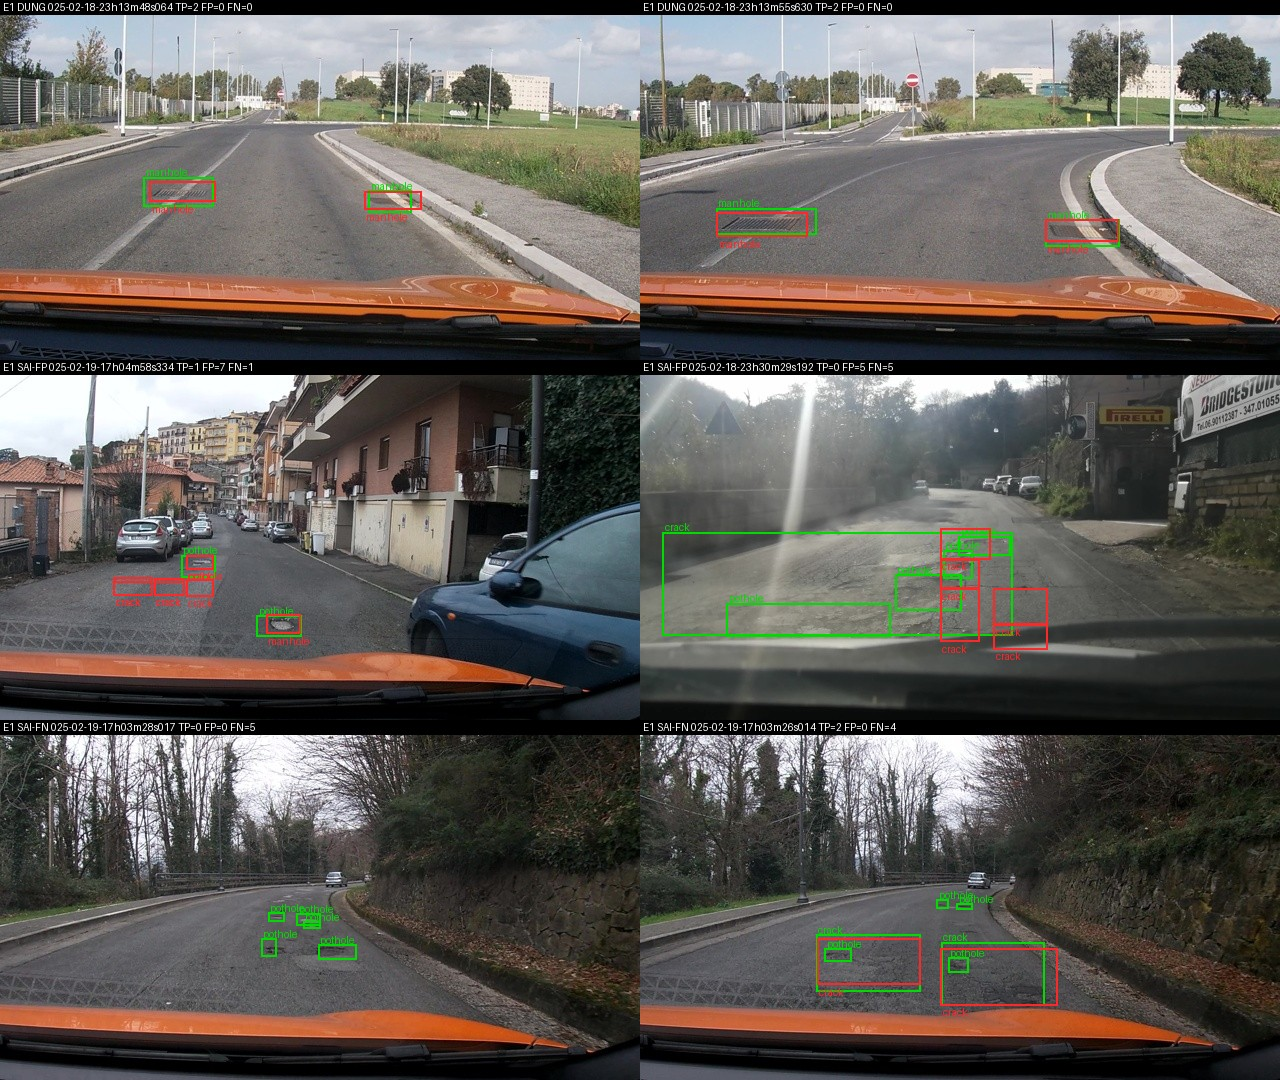

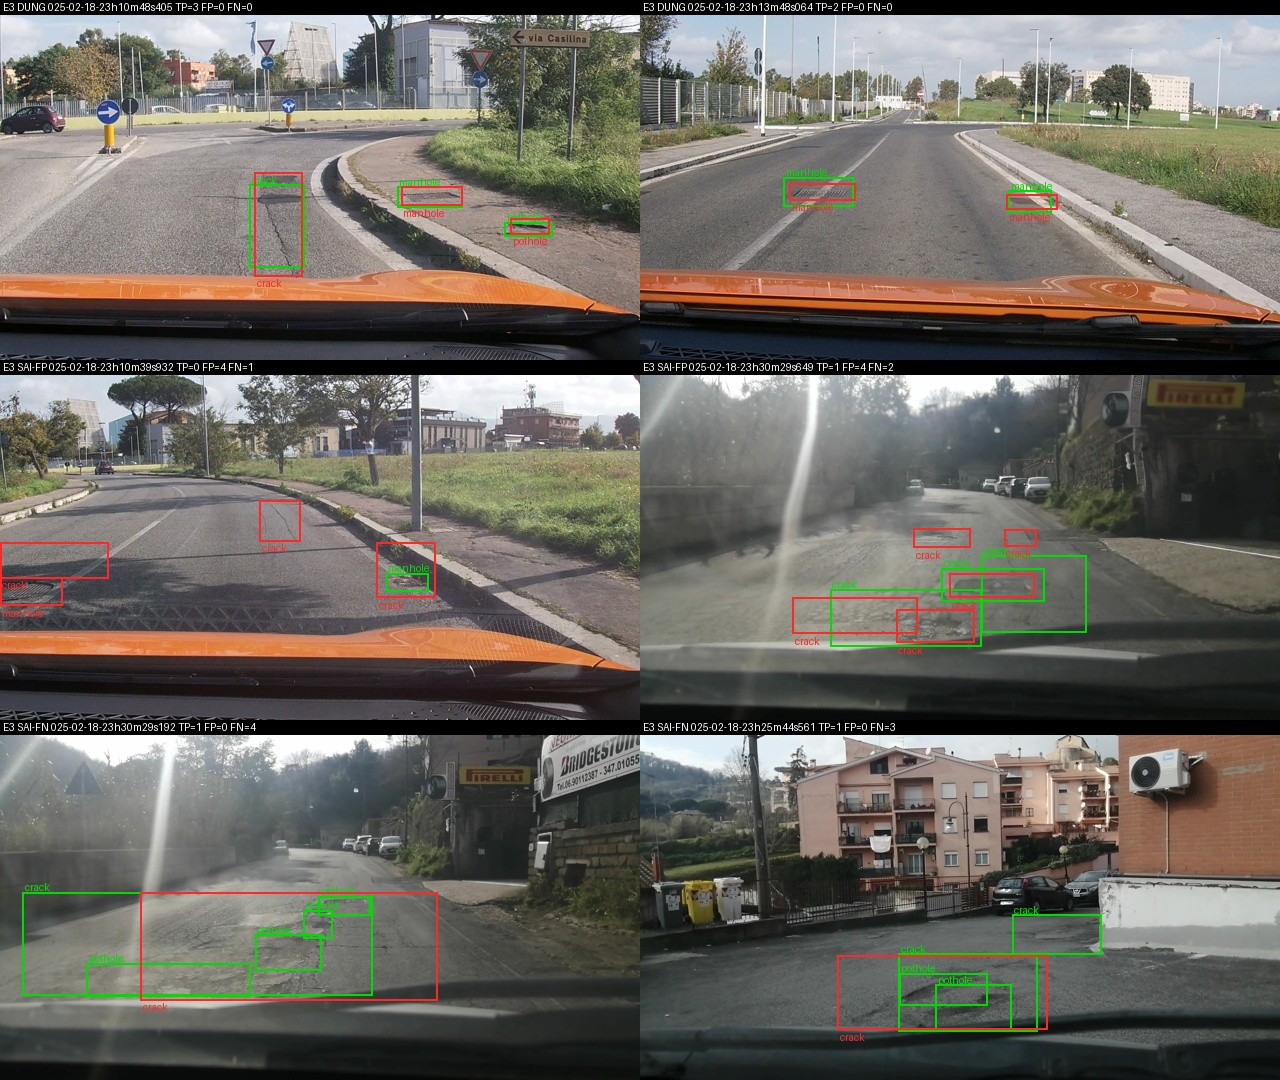

In [17]:
display(Image("report/figures/e1_examples.jpg", width=900))
display(Image("report/figures/e3_examples.jpg", width=900))

## 8. E4 (ablation `data_size`, gốc E3) và E5 (GRPO, reward IoU)

In [18]:
for k in ("e4_data_0.1", "e4_data_1.0", "e5"):
    d = json.loads(Path(f"report/evidence/{k}.json").read_text(encoding="utf-8"))
    print(f"{k:12s} F1={d['micro']['f1']:.3f} CI95={d['f1_ci95'][0]:.3f}-{d['f1_ci95'][1]:.3f} P={d['micro']['precision']:.3f} "
          f"R={d['micro']['recall']:.3f} FP/ảnh={d['fp_per_image']:.2f} valid={d['parse_valid_rate']:.3f}")
print("E4 0.1 -> 1.0: ", end="");
!python -m lab.paired runs/e4_data_0.1/out/e4_data_0.1.jsonl runs/e3/out/e3.jsonl
print("E3 -> E5    : ", end="")
!python -m lab.paired runs/e3/out/e3.jsonl runs/e5/out/e5.jsonl

e4_data_0.1  F1=0.258 CI95=0.225-0.292 P=0.232 R=0.290 FP/ảnh=1.80 valid=0.997
e4_data_1.0  F1=0.440 CI95=0.400-0.480 P=0.466 R=0.417 FP/ảnh=0.90 valid=1.000
e5           F1=0.462 CI95=0.422-0.507 P=0.527 R=0.412 FP/ảnh=0.69 valid=1.000
E4 0.1 -> 1.0: 

F1 A=0.258 B=0.440 diff=+0.182 CI95=[+0.145, +0.217] P(diff<=0)=0.000
E3 -> E5    : 

F1 A=0.440 B=0.462 diff=+0.023 CI95=[+0.002, +0.044] P(diff<=0)=0.012


In [19]:
# Nhật ký GRPO (60 bước): thống kê reward và tín hiệu reward hacking mỗi bước
import statistics as st
G = [r for r in read_jsonl("report/logs/e5_grpo_log.jsonl") if r["kind"] == "batch"]
cols = ("reward_mean", "reward_std", "invalid_frac", "empty_when_gt_frac", "pred_boxes_mean", "gt_boxes_mean", "giant_boxes")
print("bước   " + " ".join(f"{c[:12]:>12s}" for c in cols))
for i in range(0, 60, 10):
    blk = G[i:i + 10]
    print(f"{i + 1:2d}-{i + 10:2d}  " + " ".join(f"{st.mean(r[c] for r in blk):12.3f}" for c in cols))
print(json.loads(Path("report/logs/e5_run.json").read_text()))

bước    reward_mean   reward_std invalid_frac empty_when_g pred_boxes_m gt_boxes_mea  giant_boxes
 1-10         0.449        0.209        0.044        0.000        1.905        1.800        0.100
11-20         0.365        0.134        0.013        0.000        1.723        1.900        0.000
21-30         0.400        0.218        0.037        0.000        1.645        2.000        0.000
31-40         0.372        0.155        0.037        0.000        1.906        2.250        0.700
41-50         0.414        0.200        0.019        0.000        1.648        1.650        0.000
51-60         0.456        0.201        0.006        0.000        1.636        2.200        0.000
{'name': 'e5', 'impl': 'trl', 'init_adapter': '/kaggle/input/lab10-e3/out/adapter', 'init_projector': '/kaggle/input/lab10-e3/out/projector.pt', 'trainable_params': 33030144, 'train_minutes': 38.25, 'peak_vram_gb': 6.87, 'n_prompt_pool': 1280, 'num_generations': 4, 'max_completion_length': 128, 'max_steps': 60, '